# Train to test leakage in OpenVaccine

`train.json` has 2,400 RNAs, all 107 nucleotides, with measurements on the first 68. The competition `test.json` has 3,634 RNAs and no labels. It mixes two sets:

- **Public test:** 629 RNAs of length 107, scored on the first 68. Same design round as the training set (RYOS-I). This is what the public leaderboard used.
- **Private test:** 3,005 RNAs of length 130, scored on the first 91. Designed and measured later (RYOS-II), while the competition was running.

The file next to `train.json`, `test_with_labels.json`, is that same test set with the measured targets filled in from the Das Lab release of the competition data. Ids match `sample_submission.csv` and the `bpps/` filenames. Labels are what make it possible to ask whether a similar training RNA also carries the same answer.

Two things would be leakage:

1. A test RNA is a copy, or a close variant, of a training RNA, so a model can memorize the neighbor instead of learning a rule that transfers.
2. A random split of `train.json` puts near-copies on both sides, so validation error is optimistic. That is train-to-train leakage, and it matters before any test number is meaningful.

Identity below is Hamming identity on a stated window. The first 5 bases (`GGAAA`) and the last 21 (`AAAAGAAACAACAACAACAAC`) are a cassette shared by every RNA in both files, so they are removed before comparing the variable region.

## Load

In [1]:
import os
import tempfile
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", tempfile.mkdtemp(prefix="mpl-"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

DATA_CANDIDATES = [
    Path("../data/stanford-covid-vaccine"),
    Path("data/stanford-covid-vaccine"),
]
DATA = next(path for path in DATA_CANDIDATES if (path / "train.json").exists())

train = pd.read_json(DATA / "train.json", lines=True)
test = pd.read_json(DATA / "test_with_labels.json", lines=True)
submission = pd.read_csv(DATA / "sample_submission.csv", usecols=["id_seqpos"])
submission_ids = set(submission.id_seqpos.str.rsplit("_", n=1).str[0])

SCORED = ["reactivity", "deg_Mg_pH10", "deg_Mg_50C"]
PREFIX = 5
SUFFIX = 21

print("train", train.shape, "test", test.shape)
print("test ids in sample_submission", len(set(test.id) & submission_ids), "of", test.id.nunique())
print(test.groupby("seq_length").size().rename("molecules"))

Matplotlib is building the font cache; this may take a moment.


train (2400, 19) test (3634, 11)
test ids in sample_submission 3634 of 3634
seq_length
107     629
130    3005
Name: molecules, dtype: int64


## Copies, and the cassette that every RNA shares

An identical id or an identical full sequence would be a direct copy of a training example into the test file. The cassette check is separate: a shared primer is part of the experiment design, and it makes raw percent identity look higher than the variable sequence really is.

In [2]:
from typing import Any


def common_ends(sequences):
    rows = list[Any](sequences)
    prefix = rows[0]
    for seq in rows[1:]:
        n = 0
        for a, b in zip(prefix, seq):
            if a != b:
                break
            n += 1
        prefix = prefix[:n]
    suffix = rows[0][::-1]
    for seq in rows[1:]:
        rev = seq[::-1]
        n = 0
        for a, b in zip(suffix, rev):
            if a != b:
                break
            n += 1
        suffix = suffix[:n]
    return prefix, suffix[::-1]

all_seq = pd.concat([train.sequence, test.sequence], ignore_index=True)
prefix, suffix = common_ends(all_seq)
assert train.sequence.str.startswith(prefix).all()
assert test.sequence.str.startswith(prefix).all()
assert train.sequence.str.endswith(suffix).all()
assert test.sequence.str.endswith(suffix).all()

public = test[test.seq_length == 107].reset_index(drop=True)
private = test[test.seq_length == 130].reset_index(drop=True)

print("shared ids", len(set(train.id) & set(test.id)))
print("identical full sequences", len(set(train.sequence) & set(test.sequence)))
print("duplicate sequences inside train", int(train.sequence.duplicated().sum()))
print("duplicate sequences inside test", int(test.sequence.duplicated().sum()))
print(f"cassette shared by all {len(all_seq)} RNAs")
print(f"  5' ({len(prefix)} nt) {prefix}")
print(f"  3' ({len(suffix)} nt) {suffix}")
print(f"variable region is {107 - len(prefix) - len(suffix)} nt on a training RNA, {130 - len(prefix) - len(suffix)} nt on a private-test RNA")
print("public", len(public), "private", len(private))

shared ids 0
identical full sequences 0
duplicate sequences inside train 0
duplicate sequences inside test 0
cassette shared by all 6034 RNAs
  5' (5 nt) GGAAA
  3' (21 nt) AAAAGAAACAACAACAACAAC
variable region is 81 nt on a training RNA, 104 nt on a private-test RNA
public 629 private 3005


## How close is the nearest training RNA?

For the public test the sequences have the same length as the training set, so each test RNA is compared with every training RNA on the variable region (bases 5 through 85, the 81 positions that are not the cassette) and on the scored window (first 68 bases).

For the private test the sequences are longer. Two comparisons are used. The first is the length of the shared 5' prefix with the closest training RNA: a long prefix means the test construct starts as a copy of a training construct and only changes in the tail. The second is identity on the first 68 bases, which is exactly the window that has labels in `train.json`.

The same public-test comparison is repeated with the training library restricted to `SN_filter == 1`. Those are the rows that passed the host's quality cut. The host built the public test from small clusters of that filtered pool, and left the rows that failed the cut in `train.json`.

In [3]:
def as_chars(sequences):
    return np.array([list(seq) for seq in sequences], dtype="U1")

def nearest(query, library, chunk=80):
    """Hamming match count of each query row against the closest library row."""
    best = np.empty(len(query), dtype=np.int32)
    which = np.empty(len(query), dtype=np.int32)
    for start in range(0, len(query), chunk):
        block = query[start:start + chunk]
        matches = (block[:, None, :] == library[None, :, :]).sum(axis=-1)
        which[start:start + len(block)] = matches.argmax(axis=1)
        best[start:start + len(block)] = matches.max(axis=1)
    return best, which

def longest_prefix(query, library, library_len, chunk=40):
    """Longest 5' prefix of each query that exactly matches some library row."""
    best = np.empty(len(query), dtype=np.int32)
    which = np.empty(len(query), dtype=np.int32)
    head = query[:, :library_len]
    for start in range(0, len(query), chunk):
        block = head[start:start + chunk]
        agree = block[:, None, :] == library[None, :, :]
        length = np.cumprod(agree, axis=-1).sum(axis=-1)
        which[start:start + len(block)] = length.argmax(axis=1)
        best[start:start + len(block)] = length.max(axis=1)
    return best, which

def summarize(identity, thresholds):
    identity = np.asarray(identity, dtype=float)
    print(
        f"  min {identity.min():.3f}  median {np.median(identity):.3f}  "
        f"p90 {np.quantile(identity, 0.9):.3f}  max {identity.max():.3f}"
    )
    for threshold in thresholds:
        n = int((identity >= threshold).sum())
        print(f"  >= {threshold:.2f}: {n} / {len(identity)}")

train_seq = as_chars(train.sequence)
train_keep = train.SN_filter.to_numpy() == 1
train_seq_hq = train_seq[train_keep]
public_seq = as_chars(public.sequence)
private_seq = as_chars(private.sequence)

var_start, var_end = PREFIX, 107 - SUFFIX
var_len = var_end - var_start
scored_len = 68

pub_var, pub_var_i = nearest(public_seq[:, var_start:var_end], train_seq[:, var_start:var_end])
pub_var_hq, pub_var_hq_i = nearest(public_seq[:, var_start:var_end], train_seq_hq[:, var_start:var_end])
pub_scored, pub_scored_i = nearest(public_seq[:, :scored_len], train_seq[:, :scored_len])
pub_scored_hq, _ = nearest(public_seq[:, :scored_len], train_seq_hq[:, :scored_len])

# Map the high-quality argmax back onto the original train index.
hq_index = np.flatnonzero(train_keep)
pub_var_hq_i = hq_index[pub_var_hq_i]

print(f"PUBLIC variable region ({var_len} nt), nearest of all {len(train)} training RNAs")
summarize(pub_var / var_len, [0.70, 0.80, 0.90, 0.95, 1.00])
print(f"PUBLIC variable region, nearest of the {train_keep.sum()} RNAs with SN_filter = 1")
summarize(pub_var_hq / var_len, [0.70, 0.80, 0.90, 0.95, 1.00])
print("PUBLIC scored window (first 68), nearest training RNA")
summarize(pub_scored / scored_len, [0.80, 0.90, 0.95, 1.00])
print("PUBLIC scored window, nearest SN_filter = 1 training RNA")
summarize(pub_scored_hq / scored_len, [0.80, 0.90, 0.95, 1.00])

close = (pub_var / var_len) >= 0.80
print("public RNAs at >= 0.80 variable identity whose neighbor failed SN_filter:",
      int((train.SN_filter.to_numpy()[pub_var_i][close] == 0).sum()), "of", int(close.sum()))

priv_prefix, priv_prefix_i = longest_prefix(private_seq, train_seq, 107)
priv_scored, priv_scored_i = nearest(private_seq[:, :scored_len], train_seq[:, :scored_len])
priv_prefix_hq, _ = longest_prefix(private_seq, train_seq_hq, 107)
priv_scored_hq, _ = nearest(private_seq[:, :scored_len], train_seq_hq[:, :scored_len])

print("\nPRIVATE longest shared 5' prefix with any training RNA")
print(f"  min {priv_prefix.min()}  median {np.median(priv_prefix):.0f}  "
      f"p90 {np.quantile(priv_prefix, 0.9):.0f}  max {priv_prefix.max()}")
for length in (40, 68, 80, 91, 107):
    print(f"  prefix >= {length}: {int((priv_prefix >= length).sum())} / {len(private)}")
print("PRIVATE longest shared 5' prefix, library restricted to SN_filter = 1")
for length in (68, 91):
    print(f"  prefix >= {length}: {int((priv_prefix_hq >= length).sum())} / {len(private)}")
print("PRIVATE identity on the first 68 bases")
summarize(priv_scored / scored_len, [0.80, 0.90, 0.95, 1.00])
print("PRIVATE identity on the first 68, SN_filter = 1 library")
summarize(priv_scored_hq / scored_len, [0.80, 0.90, 0.95, 1.00])

# Chance level: identity of each public RNA to one random training RNA, and to a
# composition-matched shuffle of its own variable region (max over the training set).
rng = np.random.default_rng(0)
random_partner = rng.integers(0, len(train), size=len(public))
random_identity = np.array([
    (public_seq[i, var_start:var_end] == train_seq[j, var_start:var_end]).mean()
    for i, j in enumerate(random_partner)
])
null_max = np.empty(len(public))
train_var = train_seq[:, var_start:var_end]
for i in range(len(public)):
    observed = public_seq[i, var_start:var_end]
    draws = []
    for _ in range(5):
        shuffled = observed.copy()
        rng.shuffle(shuffled)
        draws.append((train_var == shuffled).sum(axis=1).max() / var_len)
    null_max[i] = np.mean(draws)
print("\nPUBLIC variable identity to one random training RNA: "
      f"median {np.median(random_identity):.3f}")
print("PUBLIC variable identity, nearest training RNA vs shuffle null (median of the per-RNA max): "
      f"{np.median(pub_var / var_len):.3f} vs {np.median(null_max):.3f}")
print("public RNAs whose real neighbor beats the shuffle null by >= 0.10:",
      int(((pub_var / var_len) > null_max + 0.10).sum()))

PUBLIC variable region (81 nt), nearest of all 2400 training RNAs
  min 0.432  median 0.519  p90 0.716  max 0.951
  >= 0.70: 75 / 629
  >= 0.80: 32 / 629
  >= 0.90: 8 / 629
  >= 0.95: 1 / 629
  >= 1.00: 0 / 629
PUBLIC variable region, nearest of the 1589 RNAs with SN_filter = 1
  min 0.432  median 0.506  p90 0.617  max 0.914
  >= 0.70: 29 / 629
  >= 0.80: 4 / 629
  >= 0.90: 1 / 629
  >= 0.95: 0 / 629
  >= 1.00: 0 / 629
PUBLIC scored window (first 68), nearest training RNA
  min 0.441  median 0.529  p90 0.735  max 0.985
  >= 0.80: 41 / 629
  >= 0.90: 13 / 629
  >= 0.95: 4 / 629
  >= 1.00: 0 / 629
PUBLIC scored window, nearest SN_filter = 1 training RNA
  min 0.441  median 0.515  p90 0.632  max 0.985
  >= 0.80: 12 / 629
  >= 0.90: 2 / 629
  >= 0.95: 1 / 629
  >= 1.00: 0 / 629
public RNAs at >= 0.80 variable identity whose neighbor failed SN_filter: 28 of 32



PRIVATE longest shared 5' prefix with any training RNA
  min 7  median 10  p90 12  max 91
  prefix >= 40: 25 / 3005
  prefix >= 68: 16 / 3005
  prefix >= 80: 4 / 3005
  prefix >= 91: 3 / 3005
  prefix >= 107: 0 / 3005
PRIVATE longest shared 5' prefix, library restricted to SN_filter = 1
  prefix >= 68: 15 / 3005
  prefix >= 91: 2 / 3005
PRIVATE identity on the first 68 bases
  min 0.426  median 0.500  p90 0.632  max 1.000
  >= 0.80: 144 / 3005
  >= 0.90: 71 / 3005
  >= 0.95: 19 / 3005
  >= 1.00: 16 / 3005
PRIVATE identity on the first 68, SN_filter = 1 library
  min 0.426  median 0.485  p90 0.603  max 1.000
  >= 0.80: 137 / 3005
  >= 0.90: 66 / 3005
  >= 0.95: 18 / 3005
  >= 1.00: 15 / 3005



PUBLIC variable identity to one random training RNA: median 0.309
PUBLIC variable identity, nearest training RNA vs shuffle null (median of the per-RNA max): 0.519 vs 0.427
public RNAs whose real neighbor beats the shuffle null by >= 0.10: 245


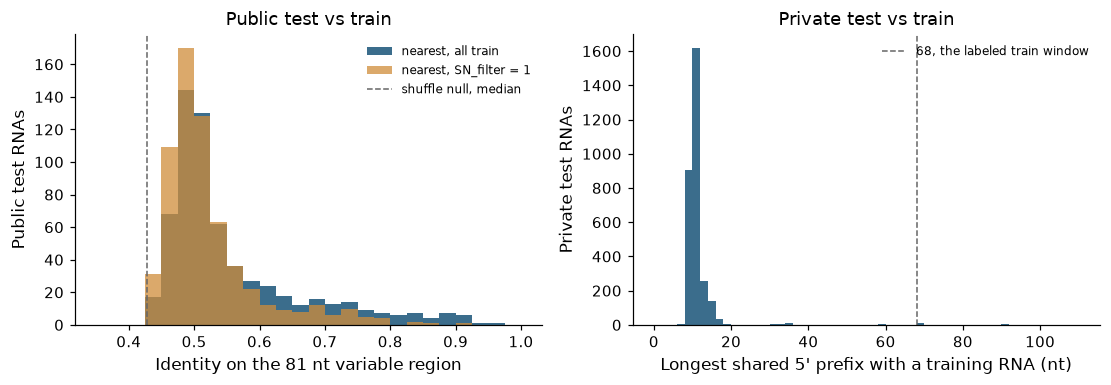

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.6))

bins = np.linspace(0.35, 1.0, 27)
axes[0].hist(pub_var / var_len, bins=bins, color="#3b6d8c", label="nearest, all train")
axes[0].hist(pub_var_hq / var_len, bins=bins, color="#d08c3a", alpha=0.75, label="nearest, SN_filter = 1")
axes[0].axvline(np.median(null_max), color="#666666", ls="--", lw=1, label="shuffle null, median")
axes[0].set_xlabel("Identity on the 81 nt variable region")
axes[0].set_ylabel("Public test RNAs")
axes[0].set_title("Public test vs train")
axes[0].legend(frameon=False, fontsize=8)

axes[1].hist(priv_prefix, bins=np.arange(0, 112, 2), color="#3b6d8c")
axes[1].axvline(68, color="#666666", ls="--", lw=1, label="68, the labeled train window")
axes[1].set_xlabel("Longest shared 5' prefix with a training RNA (nt)")
axes[1].set_ylabel("Private test RNAs")
axes[1].set_title("Private test vs train")
axes[1].legend(frameon=False, fontsize=8)

fig.tight_layout()
plt.show()

## The closest pairs

Variable-region identity of 0.80 on the public test is about 16 differences across the 81 bases that are not the cassette. The private-test rows below are the ones whose 5' end copies a training RNA through the whole labeled window.

In [5]:
public_neighbors = pd.DataFrame({
    "test_id": public.id,
    "train_id": train.id.to_numpy()[pub_var_i],
    "variable_identity": pub_var / var_len,
    "scored68_identity": (public_seq[:, :scored_len] == train_seq[pub_var_i, :scored_len]).mean(axis=1),
    "neighbor_SN_filter": train.SN_filter.to_numpy()[pub_var_i],
    "neighbor_signal_to_noise": train.signal_to_noise.to_numpy()[pub_var_i],
}).sort_values("variable_identity", ascending=False)

print("Closest public-test RNAs")
print(public_neighbors.head(12).round(3).to_string(index=False))

private_neighbors = pd.DataFrame({
    "test_id": private.id,
    "train_id": train.id.to_numpy()[priv_prefix_i],
    "shared_prefix": priv_prefix,
    "scored68_identity": priv_scored / scored_len,
    "neighbor_SN_filter": train.SN_filter.to_numpy()[priv_prefix_i],
    "neighbor_signal_to_noise": train.signal_to_noise.to_numpy()[priv_prefix_i],
}).sort_values(["shared_prefix", "scored68_identity"], ascending=False)

copied_prefix = private_neighbors[private_neighbors.shared_prefix >= 68]
print(f"\nPrivate-test RNAs whose 5' prefix copies a training RNA for >= 68 nt: {len(copied_prefix)}")
print(copied_prefix.round(3).to_string(index=False))

# Exact containment of a training variable region inside a longer private RNA.
train_core = {
    seq[PREFIX:-SUFFIX]: rna_id
    for seq, rna_id in zip(train.sequence, train.id)
}
contained = []
for rna_id, seq in zip(private.id, private.sequence):
    core = seq[PREFIX:-SUFFIX]
    for start in range(0, len(core) - var_len + 1):
        hit = train_core.get(core[start:start + var_len])
        if hit is not None:
            contained.append((rna_id, hit, PREFIX + start))
            break
print(f"\nPrivate RNAs that contain some training variable region exactly: {len(contained)}")
for row in contained:
    print(" ", row[0], "contains", row[1], "starting at position", row[2])

Closest public-test RNAs
     test_id     train_id  variable_identity  scored68_identity  neighbor_SN_filter  neighbor_signal_to_noise
id_cd116efd5 id_589ae1f6f              0.951              0.971                   0                     3.900
id_e780fc5e0 id_0743380fa              0.938              0.956                   0                     0.919
id_a93c9dc87 id_85291c84e              0.914              0.941                   0                     5.037
id_2fe0794e9 id_d06fade81              0.914              0.926                   0                     0.443
id_614b94f40 id_f1195ab2f              0.914              0.926                   0                     0.000
id_9a521e5a2 id_60bbf0297              0.914              0.926                   1                     3.344
id_4b9e2063e id_2714124a2              0.914              0.956                   0                     4.304
id_a833c2ed7 id_f88c7c3da              0.901              0.912                   0            

## Do the close pairs share the measured labels?

Sequence similarity is only leakage of the answer if the targets agree too. For each test RNA the three scored targets are compared, on the first 68 positions, with its nearest training neighbor and with a random training RNA. The number reported is MCRMSE, the same average of per-target RMSEs used to score the competition. Lower means the training neighbor already has the test RNA's labels.

In [6]:
def label_matrix(frame, n_positions):
    mats = []
    for column in SCORED:
        rows = [
            [np.nan if value is None else float(value) for value in values[:n_positions]]
            for values in frame[column]
        ]
        mats.append(np.asarray(rows, dtype=float))
    return np.stack(mats, axis=0)

def pair_mcrmse(test_y, train_y, partner):
    copied = train_y[:, partner, :]
    rmse = np.sqrt(np.nanmean((test_y - copied) ** 2, axis=-1))
    return rmse.mean(axis=0)

train_y = label_matrix(train, 68)
public_y = label_matrix(public, 68)
private_y = label_matrix(private, 68)

public_nn_error = pair_mcrmse(public_y, train_y, pub_var_i)
public_random_error = pair_mcrmse(public_y, train_y, random_partner)
private_nn_error = pair_mcrmse(private_y, train_y, priv_prefix_i)
private_random_partner = rng.integers(0, len(train), size=len(private))
private_random_error = pair_mcrmse(private_y, train_y, private_random_partner)

def report_errors(name, identity, error, random_error, high):
    print(name)
    print(f"  all:    median MCRMSE vs neighbor {np.median(error):.3f}   vs random train {np.median(random_error):.3f}")
    mask = high
    if mask.any():
        print(f"  close subset n={int(mask.sum())}: median MCRMSE vs neighbor {np.median(error[mask]):.3f}")

report_errors(
    "PUBLIC (neighbor chosen by variable-region identity)",
    pub_var / var_len,
    public_nn_error,
    public_random_error,
    (pub_var / var_len) >= 0.80,
)
report_errors(
    "PRIVATE (neighbor chosen by longest shared prefix)",
    priv_prefix,
    private_nn_error,
    private_random_error,
    priv_prefix >= 68,
)

copied = private_neighbors.shared_prefix.to_numpy() >= 68
# private_neighbors was sorted, so align errors through the original prefix index
print("\nLabel error on private RNAs with a copied prefix of >= 68")
detail = private_neighbors.copy()
# recover error via the unsorted priv_prefix arrays
error_by_test = dict(zip(private.id, private_nn_error))
detail["mcrmse_vs_neighbor"] = detail.test_id.map(error_by_test)
print(detail.round(3).query("shared_prefix >= 68").to_string(index=False))

PUBLIC (neighbor chosen by variable-region identity)
  all:    median MCRMSE vs neighbor 0.549   vs random train 0.596
  close subset n=32: median MCRMSE vs neighbor 0.383
PRIVATE (neighbor chosen by longest shared prefix)
  all:    median MCRMSE vs neighbor 0.688   vs random train 0.681
  close subset n=16: median MCRMSE vs neighbor 0.411

Label error on private RNAs with a copied prefix of >= 68
     test_id     train_id  shared_prefix  scored68_identity  neighbor_SN_filter  neighbor_signal_to_noise  mcrmse_vs_neighbor
id_002852873 id_0f1f87d49             91                1.0                   1                    10.563               0.147
id_0d6a71f64 id_abfe92811             91                1.0                   1                     6.514               0.298
id_2eeea0fb4 id_8c88963e9             91                1.0                   0                     6.068               0.658
id_b89905e88 id_ce3a55e44             90                1.0                   1                

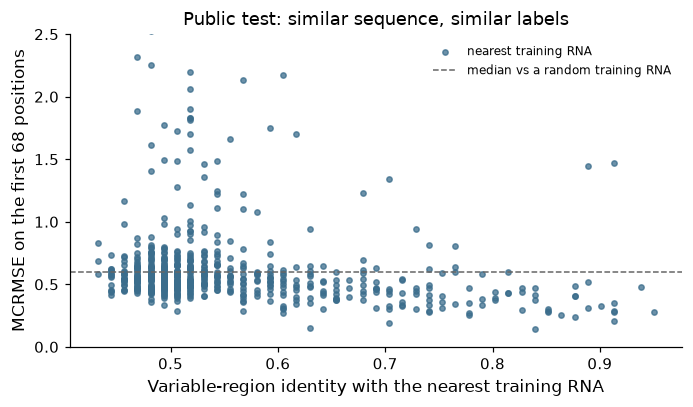

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.scatter(pub_var / var_len, public_nn_error, s=12, c="#3b6d8c", alpha=0.75, label="nearest training RNA")
ax.axhline(np.median(public_random_error), color="#666666", ls="--", lw=1, label="median vs a random training RNA")
ax.set_xlabel("Variable-region identity with the nearest training RNA")
ax.set_ylabel("MCRMSE on the first 68 positions")
ax.set_title("Public test: similar sequence, similar labels")
ax.set_ylim(0, min(2.5, np.nanpercentile(public_nn_error, 99)))
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

## The training set is more redundant than the test split

Most of the near-duplicate problem is inside `train.json`. Eterna players submitted clusters of small edits of one design. A random row split puts those edits on both sides of the split, and the validation score then partly measures memorization. The host's own competition split tried to avoid this by clustering at 50% sequence identity and drawing the public test from clusters of size at most 3. That clustering was not applied to the rows with `SN_filter = 0`, and it still allows a test RNA to have one or two close relatives in the training file.

In [8]:
def nearest_other(library, chunk=64):
    best = np.empty(len(library), dtype=np.int32)
    which = np.empty(len(library), dtype=np.int32)
    for start in range(0, len(library), chunk):
        block = library[start:start + chunk]
        matches = (block[:, None, :] == library[None, :, :]).sum(axis=-1)
        for k in range(len(block)):
            matches[k, start + k] = -1
        which[start:start + len(block)] = matches.argmax(axis=1)
        best[start:start + len(block)] = matches.max(axis=1)
    return best, which

train_nn, train_nn_i = nearest_other(train_seq[:, var_start:var_end])
train_identity = train_nn / var_len
print("WITHIN TRAIN, identity to the nearest other RNA on the 81 nt variable region")
summarize(train_identity, [0.70, 0.80, 0.90, 0.95, 1.00])

# Same check restricted to the filtered rows a model would actually train on.
hq_nn, _ = nearest_other(train_seq_hq[:, var_start:var_end])
print(f"WITHIN the {train_keep.sum()} SN_filter = 1 RNAs")
summarize(hq_nn / var_len, [0.70, 0.80, 0.90, 0.95, 1.00])

# Predicted structure is an input, not a target. Count exact reuse anyway.
print("\npublic test RNAs with a structure string that also appears in train:",
      int(public.structure.isin(set(train.structure)).sum()), "of", len(public))
print("private test RNAs whose first 68 structure characters match some training RNA:",
      int(nearest(as_chars(private.structure)[:, :68], as_chars(train.structure)[:, :68])[0].__eq__(68).sum()),
      "of", len(private))

WITHIN TRAIN, identity to the nearest other RNA on the 81 nt variable region
  min 0.432  median 0.889  p90 0.975  max 0.988
  >= 0.70: 1853 / 2400
  >= 0.80: 1681 / 2400
  >= 0.90: 1194 / 2400
  >= 0.95: 690 / 2400
  >= 1.00: 0 / 2400


WITHIN the 1589 SN_filter = 1 RNAs
  min 0.432  median 0.889  p90 0.975  max 0.988
  >= 0.70: 1245 / 1589
  >= 0.80: 1093 / 1589
  >= 0.90: 728 / 1589
  >= 0.95: 355 / 1589
  >= 1.00: 0 / 1589

public test RNAs with a structure string that also appears in train: 48 of 629


private test RNAs whose first 68 structure characters match some training RNA: 236 of 3005


## Reading of the split

There is no copied id and no copied full sequence. Every RNA in both files does share a 26-nucleotide cassette (`GGAAA` at the 5' end, `AAAAGAAACAACAACAACAAC` at the 3' end). That cassette is the experiment, not a leaked example. The identity numbers above are computed after removing it.

**Public test (629 RNAs, same design round as train).** The nearest training neighbor on the 81 nt variable region has median identity 0.519, against 0.427 for a composition-matched shuffle and 0.309 for one random training RNA. Most public RNAs are from the same pool, not copies of a training row. A minority are close: 32/629 are at least 0.80 identical, 8/629 at least 0.90, and one reaches 0.951. None are exact. Of those 32 neighbors, 28 failed `SN_filter`. Restricting the library to the 1,589 rows with `SN_filter = 1` leaves 4 public RNAs at or above 0.80 and 1 at or above 0.90. On the 32 close pairs, median MCRMSE against the neighbor is 0.383, compared with 0.596 against a random training RNA, so the labels move with the sequence. Across all public RNAs the gap is small (0.549 vs 0.596). 48 public RNAs also reuse a predicted structure string that appears in train.

**Private test (3,005 RNAs, the blind set).** The median longest shared 5' prefix is 10 nt, just past the cassette. 16/3005 share a prefix of at least 68 nt, which is the entire window labeled in `train.json`, and 3 of those extend to 91 nt, the window scored on the private test. Four private RNAs contain an exact copy of some training variable region, starting at position 5. Filtering to `SN_filter = 1` removes only 1 of the 16 long prefixes. Median MCRMSE on those 16 is 0.411, against 0.681 for a random training RNA. A few are tight (0.147 and 0.162) and a few are not (about 0.99): a copied prefix does not always copy the measurement, because the extra 3' sequence can change degradation on the shared positions. For the other 2,989 private RNAs, label error against the nearest prefix is the same as against a random training RNA (0.688 vs 0.681).

**Inside `train.json`.** This is the larger problem for model selection. Median identity to the nearest other training RNA, on the variable region, is 0.889. 1,194/2,400 training RNAs have a neighbor at or above 0.90, and 690/2,400 at or above 0.95. Restricting to `SN_filter = 1` does not change the median (still 0.889; 728/1,589 at or above 0.90). A random row split puts edits of the same design on both sides. Hold out whole groups of similar sequences.


## Train / validation split

One split of `train.json`. Two RNAs are linked when at least 80% of the 81 variable-region positions match, and the link is transitive, so a chain of edits stays on one side. Each connected group goes entirely to train or to validation. Within singletons, groups of 2–5, and groups of 6 or more, groups are drawn until about 15% of the molecules in that size bin are in validation. The test set is not used.

In [9]:
IDENTITY_CUTOFF = 0.80
VAL_FRACTION = 0.15
SPLIT_SEED = 0
# matches / 81 >= 0.80  <=>  matches >= 65
cutoff_matches = int(np.ceil(IDENTITY_CUTOFF * var_len - 1e-9))

parent = np.arange(len(train))

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

variable = train_seq[:, var_start:var_end]
for start in range(0, len(train), 100):
    block = variable[start:start + 100]
    matches = (block[:, None, :] == variable[None, :, :]).sum(axis=-1)
    rows = np.arange(block.shape[0])[:, None]
    cols = np.arange(len(train))[None, :]
    hit = (matches >= cutoff_matches) & (cols > start + rows)
    ii, jj = np.where(hit)
    for a, b in zip(ii, jj):
        union(start + int(a), int(b))

roots = np.array([find(i) for i in range(len(train))])
_, cluster_id = np.unique(roots, return_inverse=True)
cluster_size = np.bincount(cluster_id)
n_clusters = cluster_size.size

def size_bin(size):
    if size == 1:
        return "1"
    if size <= 5:
        return "2-5"
    return "6+"

rng = np.random.default_rng(SPLIT_SEED)
val_clusters = []
for label in ("1", "2-5", "6+"):
    members = np.array([c for c in range(n_clusters) if size_bin(cluster_size[c]) == label])
    order = rng.permutation(members)
    target = VAL_FRACTION * cluster_size[members].sum()
    taken = 0
    for cluster in order:
        if taken >= target:
            break
        val_clusters.append(int(cluster))
        taken += int(cluster_size[cluster])

is_val = np.isin(cluster_id, val_clusters)
val_variable = variable[is_val]
train_variable = variable[~is_val]
cross_matches, _ = nearest(val_variable, train_variable)
cross_identity = cross_matches / var_len

print(f"cutoff: {cutoff_matches}/{var_len} matches ({cutoff_matches / var_len:.3f})")
print(f"clusters: {n_clusters}")
print(f"train molecules: {(~is_val).sum()}    val molecules: {is_val.sum()}")
print(f"train SN_filter = 1: {int((~is_val & train_keep).sum())}    "
      f"val SN_filter = 1: {int((is_val & train_keep).sum())}")
print(f"max variable-region identity across the split: {cross_identity.max():.3f}")
print(f"val molecules with a train neighbor >= {IDENTITY_CUTOFF:.2f}: "
      f"{int((cross_identity >= IDENTITY_CUTOFF).sum())}")

bin_rows = []
for label in ("1", "2-5", "6+"):
    members = np.array([c for c in range(n_clusters) if size_bin(cluster_size[c]) == label])
    in_val = np.isin(members, val_clusters)
    bin_rows.append({
        "cluster_size": label,
        "clusters": len(members),
        "val_clusters": int(in_val.sum()),
        "molecules": int(cluster_size[members].sum()),
        "val_molecules": int(cluster_size[members][in_val].sum()),
    })
print(pd.DataFrame(bin_rows).to_string(index=False))

assignment = pd.DataFrame({
    "id": train.id.to_numpy(),
    "split": np.where(is_val, "val", "train"),
    "cluster": cluster_id,
})
split_path = DATA / "split.csv"
train_path = DATA / "train_split.json"
val_path = DATA / "val_split.json"
assignment.to_csv(split_path, index=False)
train.loc[~is_val].to_json(train_path, orient="records", lines=True)
train.loc[is_val].to_json(val_path, orient="records", lines=True)

reloaded_val = pd.read_json(val_path, lines=True)
reloaded_train = pd.read_json(train_path, lines=True)
assert set(reloaded_val.id).isdisjoint(set(reloaded_train.id))
assert set(reloaded_val.id) | set(reloaded_train.id) == set(train.id)
assert len(reloaded_val) + len(reloaded_train) == len(train)
print("wrote", split_path)
print("wrote", train_path)
print("wrote", val_path)


cutoff: 65/81 matches (0.802)
clusters: 989
train molecules: 2029    val molecules: 371
train SN_filter = 1: 1330    val SN_filter = 1: 259
max variable-region identity across the split: 0.790
val molecules with a train neighbor >= 0.80: 0
cluster_size  clusters  val_clusters  molecules  val_molecules
           1       719           108        719            108
         2-5       195            32        539             82
          6+        75            19       1142            181
wrote ../data/stanford-covid-vaccine/split.csv
wrote ../data/stanford-covid-vaccine/train_split.json
wrote ../data/stanford-covid-vaccine/val_split.json
